In [1]:
import math
import numpy as np
import tensorflow as tf

from plotly.subplots import make_subplots
import plotly.graph_objects as go

from tf_ofcs.components import *
from tf_ofcs.datatypes import ElectricalSignal, OpticalSignal
from tf_ofcs.utils import dbm_to_w, from_db, to_tensor
from tf_ofcs.plot import *

2025-03-01 16:11:30.415950: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-01 16:11:30.457200: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-01 16:11:30.457230: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-01 16:11:30.458484: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-01 16:11:30.464665: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-01 16:11:30.465100: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = False

data_rate = 10e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = 2e-3 # Watts

lpf = BandPassFilter(min_frequency=[0.0], max_frequency=[1 * data_rate], name="lpf")

bits_per_symbol = 2

channel_osnr = 30.0

channel = Composition([
    OpticalAWGN(relative_db=[-channel_osnr], name="channel_noise"),
    OpticalFiber(
        attenuation=[0.22],
        length=[40.0],
        chromatic_dispersion=[17.0],
        eff_non_linear_coeff=[1.76],
        central_frequency=central_frequency,
        step_count=1000,
        name="fiber"
    )
], name="channel")

input_laser = Laser(power=[input_power], name="laser")

photodiode = Composition([Photodiode(), Quantizer(step=[1e-4]), lpf])

transmitter = Composition([
    PAMEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=PAMSymbolEncoder(
            bits_per_symbol=bits_per_symbol,
            adjust_for_mzm=True,
            name="pam_symbol_encoder"
        )
    ),
    Composition([lpf], name="encoder_output"),
    Fork(shape=[2]),
    MapComponents([input_laser, Identity()]),
    MachZehnderModulator(name="modulator")
], name="transmitter")

receiver = Composition([
    Composition([photodiode], name="receiver_output"),
    ElectricalGain(gain=[1.0]),
    PAMDecoder(
        data_rate=data_rate,
        symbol_decoder=PAMSymbolDecoder(
            bits_per_symbol=bits_per_symbol,
            name="pam_symbol_decoder"
        ),
        name="decoder_output"
    )
])

system = Composition([transmitter, channel, receiver])
channel_loss_estimator = ChannelLossEstimator(
    laser=input_laser,
    photodiode=photodiode,
    channel=channel,
    sampling_rate=1e9
)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester(system)

In [3]:
input_signal = tf.constant([[1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1]], dtype=tf.int32)
input_signal = rng.uniform((1, 512), 0, 2, dtype=tf.int32)

data_rate = 10e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = dbm_to_w(3.0) # Watts

bits_per_symbol = 2
channel_osnr = 30.0
cutoff_frequency = 2.0 * data_rate

system_params = dict(
    laser__power=to_tensor([input_power]),
    fiber__step_count=to_tensor(1),
    fiber__length=to_tensor([20.0]),
    fiber__eff_non_linear_coeff=to_tensor([1.76 * 0]),
    fiber__chromatic_dispersion=to_tensor([17.0 * 0]),
    pam_encoder__data_rate=tf.constant(data_rate),
    pam_encoder__sampling_rate=tf.constant(sampling_rate),
    decoder_output__data_rate=tf.constant(data_rate),
    pam_symbol_encoder__bits_per_symbol=tf.constant(bits_per_symbol),
    pam_symbol_decoder__bits_per_symbol=tf.constant(bits_per_symbol),
    channel_noise__relative_db=to_tensor([-channel_osnr]),
    lpf__max_frequency=to_tensor([cutoff_frequency]),
    quantizer__step=to_tensor([1e-6]),
    batch_size=tf.shape(input_signal)[0],
    photodiode__sensitivity=dbm_to_w([-20.0]),
    photodiode__maximum_power=dbm_to_w([3.0])
)

estimated_channel_loss = channel_loss_estimator(1000e-9, **system_params)[0]

symbol_scale = input_power / estimated_channel_loss
system_params["electrical_gain__gain"] = to_tensor([1.0 / symbol_scale])

%time system.trace(input_signal, **system_params)

CPU times: user 602 ms, sys: 3.05 ms, total: 605 ms
Wall time: 607 ms


<tf.Tensor: shape=(1, 512), dtype=int32, numpy=
array([[0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
        1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1,
        0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0,
        1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
        1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,
        1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
        1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
        0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0,
        1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
        1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0,
        1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0,

In [4]:
def plot(chromatic_dispersion, eff_non_linear_coeff, fiber_length, attenuation, osnr):
    params = dict(system_params)
    params["fiber__chromatic_dispersion"] = to_tensor([chromatic_dispersion])
    params["fiber__eff_non_linear_coeff"] = to_tensor([eff_non_linear_coeff])
    params["fiber__length"] = to_tensor([fiber_length])
    params["fiber__attenuation"] = to_tensor([attenuation])
    params["channel_noise__relative_db"] = to_tensor([-osnr])

    estimated_channel_loss = channel_loss_estimator(1000e-9, **params)[0]

    symbol_scale = input_power / estimated_channel_loss
    params["electrical_gain__gain"] = to_tensor([1.0 / symbol_scale])
    
    system.trace(input_signal, **params)

    fig = make_subplots(
        rows=3,
        cols=2,
        subplot_titles=(
            "Input sequence", "Decoded sequence",
            "Encoded signal", "Output signal",
            "Signal after fiber", "Received signal"
        ),
        vertical_spacing = 0.05
    )

    plot_bitseq(input_signal, fig, 0, row=1, col=1)
    plot_bitseq(system.output, fig, row=1, col=2)
    plot_envelope(system.find_child("encoder_output").output, fig, row=2, col=1)
    plot_power(system.find_child("modulator").output, fig, row=2, col=2)
    plot_power(system.find_child("channel").output, fig, row=3, col=1)
    
    plot_envelope(system.find_child("receiver_output").output, fig, row=3, col=2)

    fig.update_layout(
        autosize=True,
        height=1000
    )

    return fig


import ipywidgets

ipywidgets.interact(
    plot,
    chromatic_dispersion=(-100.0, 100.0, 1.0),
    eff_non_linear_coeff=(0.0, 50000.0, 1.0),
    fiber_length=(10.0, 50.0, 1.0),
    attenuation=(0.0, 1.0, 0.01),
    osnr=(-10.0, 80.0, 1.0)
)

interactive(children=(FloatSlider(value=0.0, description='chromatic_dispersion', min=-100.0, step=1.0), FloatS…

<function __main__.plot(chromatic_dispersion, eff_non_linear_coeff, fiber_length, attenuation, osnr)>

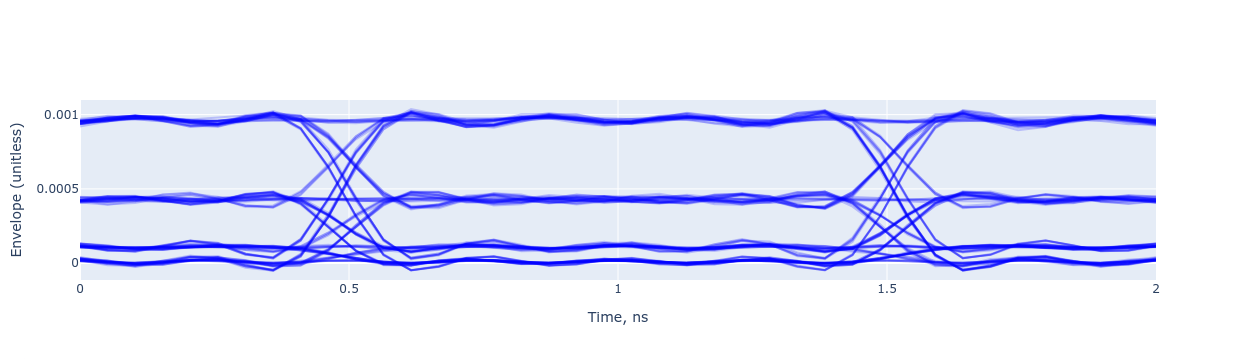

In [10]:
signal = system.find_child("receiver_output").output
fig = plot_eye_diagram(signal, symbol_rate=data_rate / bits_per_symbol, line={"color": "rgba(0, 0, 255, 0.2)"})
fig.show()

In [12]:
%time ber_tester(tf.constant(128), **system_params, ber_tester__n_iterations=tf.constant(4), ber_tester__batch_size=tf.constant(5000))

CPU times: user 5.07 s, sys: 1.43 s, total: 6.49 s
Wall time: 2.39 s


<tf.Tensor: shape=(), dtype=float32, numpy=7.421875e-06>